# 实验四 D 从零实现双尺度 YOLO 安全帽目标检测

使用 [Hard Hat Detection](https://www.kaggle.com/datasets/andrewmvd/hard-hat-detection) 的 [Voxel51 公开镜像](https://huggingface.co/datasets/Voxel51/hard-hat-detection)。数据包含 helmet、head、person 三类；person 指原标注中的人员框，head 为未戴帽的头部。镜像保留原数据的归一化左上角 xywh 框及 difficult、truncated、occluded 属性。

自行用 PyTorch 实现受 [YOLOv3](https://arxiv.org/abs/1804.02767) 启发的轻量模型：卷积骨干、双尺度特征融合、anchor 分配、边框/目标性/分类损失、解码、逐类 NMS 和 AP 计算。全部权重随机初始化，不调用现成 YOLO 检测器、预训练检测权重或训练器。这是教学用简化 YOLO，不声称复现标准 YOLOv3 的网络规模和基准成绩。

CPU 实验下载 1600 张图片，先纳入所有含稀少 person 类的图像，其余按种子 42 抽样。按近重复图像分组划分训练、验证和测试，避免完全相同或高度相似图片跨集合。

In [1]:
from pathlib import Path
import random, json, copy, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset

ROOT = Path.cwd() if (Path.cwd() / "exp4").is_dir() else Path.cwd().parent
BASE = ROOT / "exp4"
DATA = BASE / "data"
CACHE = BASE / ".cache" / "exp4D"
RESULT = BASE / "results" / "exp4D"
for folder in [DATA, CACHE, RESULT]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
                     "axes.unicode_minus": False, "figure.dpi": 110})
print("Python:", sys.executable, "设备:", device)

Python: D:\Anaconda\python.exe 设备: cpu


## 1 下载 标注转换与分组划分

In [2]:
import requests, hashlib
from concurrent.futures import ThreadPoolExecutor
from collections import Counter
from PIL import Image, ImageEnhance, ImageDraw
from sklearn.model_selection import GroupShuffleSplit
from sklearn.cluster import KMeans
import torch.nn.functional as F
from torchvision.ops import box_iou, batched_nms, generalized_box_iou_loss
from matplotlib.patches import Rectangle

def download(url, path):
    path = Path(path)
    if path.exists() and path.stat().st_size > 0:
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(4):
        try:
            r = requests.get(url, timeout=60)
            r.raise_for_status()
            tmp = path.with_suffix(path.suffix + '.download')
            tmp.write_bytes(r.content)
            tmp.replace(path)
            return
        except Exception:
            if attempt == 3:
                raise
            time.sleep(1)


raw_path=DATA/"helmet_raw.json"
download("https://huggingface.co/datasets/Voxel51/hard-hat-detection/resolve/main/samples.json",raw_path)
def helmet_data():
    raw = json.loads((DATA / 'helmet_raw.json').read_text(encoding='utf-8'))['samples']
    # 提高少数 person 类的覆盖；选择发生在划分之前，不使用模型预测。
    person = [r for r in raw if any(d['label'] == 'person' for d in r['ground_truth']['detections'])]
    other = [r for r in raw if r not in person]
    random.Random(SEED).shuffle(person)
    random.Random(SEED).shuffle(other)
    rows = person + other[:max(0, 1600 - len(person))]
    def one(row):
        filename = Path(row['filepath']).name
        path = DATA / 'helmet/images' / filename
        download('https://huggingface.co/datasets/Voxel51/hard-hat-detection/resolve/main/data/' + filename, path)
        with Image.open(path) as im:
            im.verify()
        return dict(filename=filename, detections=row['ground_truth']['detections'],
                    metadata=row['metadata'], sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    done = []
    with ThreadPoolExecutor(16) as executor:
        for i, row in enumerate(executor.map(one, rows), 1):
            done.append(row)
            if i % 200 == 0: print('HELMET', i, '/', len(rows), flush=True)
    (DATA / 'helmet/manifest_raw.json').write_text(json.dumps(done, ensure_ascii=False), encoding='utf-8')
    print('HELMET READY', len(done), 'person images', len(person), flush=True)


manifest_path=DATA/"helmet/manifest_raw.json"
if not manifest_path.exists():helmet_data()
raw_rows=json.loads(manifest_path.read_text(encoding="utf-8"))
names=["helmet","head","person"]
records=[];seen=set();invalid=0
for row in raw_rows:
    if row["sha256"] in seen:continue
    seen.add(row["sha256"])
    boxes=[];labels=[];occluded=[]
    for d in row["detections"]:
        x,y,w,h=d["bounding_box"]
        b=np.clip([x,y,x+w,y+h],0,1)
        if d["label"] not in names or b[2]<=b[0] or b[3]<=b[1]:invalid+=1;continue
        boxes.append(b.tolist());labels.append(names.index(d["label"]));occluded.append(int(d.get("occluded",0)))
    if boxes:records.append(dict(filename=row["filename"],sha256=row["sha256"],boxes=boxes,labels=labels,occluded=occluded))

# 64位差值感知哈希，相差不超过4位的图像合为一组；完全重复先删除。
hashes=[]
for row in records:
    with Image.open(DATA/"helmet/images"/row["filename"]) as im:
        a=np.array(im.convert("L").resize((9,8)))
    hashes.append(int("".join(map(str,(a[:,1:]>a[:,:-1]).astype(int).ravel())),2))
parent=list(range(len(records)))
def find(i):
    while parent[i]!=i:parent[i]=parent[parent[i]];i=parent[i]
    return i
for i in range(len(records)):
    for j in range(i):
        if (hashes[i]^hashes[j]).bit_count()<=4:parent[find(i)]=find(j)
groups=np.array([find(i) for i in range(len(records))])
train_ids,remaining=next(GroupShuffleSplit(n_splits=1,test_size=0.3,random_state=SEED).split(records,groups=groups))
v,t=next(GroupShuffleSplit(n_splits=1,test_size=0.5,random_state=SEED).split(remaining,groups=groups[remaining]))
val_ids,test_ids=remaining[v],remaining[t]
for split,ids in [("train",train_ids),("val",val_ids),("test",test_ids)]:
    for i in ids:records[i]["split"]=split;records[i]["group"]=int(groups[i])
assert set(groups[train_ids]).isdisjoint(groups[val_ids]) and set(groups[train_ids]).isdisjoint(groups[test_ids]) and set(groups[val_ids]).isdisjoint(groups[test_ids])

# 归一化左上角xywh -> 裁剪后的xyxy -> YOLO中心xywh，转换结果可直接核查。
label_dir=DATA/"helmet/labels";label_dir.mkdir(exist_ok=True)
for row in records:
    lines=[]
    for b,c in zip(row["boxes"],row["labels"]):
        x1,y1,x2,y2=b
        lines.append(f"{c} {(x1+x2)/2:.8f} {(y1+y2)/2:.8f} {x2-x1:.8f} {y2-y1:.8f}")
    (label_dir/(Path(row["filename"]).stem+".txt")).write_text("\n".join(lines),encoding="utf-8")
split_table=pd.DataFrame([dict(filename=r["filename"],split=r["split"],group=r["group"],sha256=r["sha256"],objects=len(r["labels"])) for r in records])
split_table.to_csv(RESULT/"image_split.csv",index=False)
(RESULT/"annotations.json").write_text(json.dumps(records,ensure_ascii=False),encoding="utf-8")
counts=[]
for split in ["train","val","test"]:
    count=Counter(c for r in records if r["split"]==split for c in r["labels"])
    counts.append(dict(split=split,images=sum(r["split"]==split for r in records),**{names[c]:count[c] for c in range(3)}))
count_df=pd.DataFrame(counts);count_df.to_csv(RESULT/"class_distribution.csv",index=False)
display(count_df)
print("下载",len(raw_rows),"去重后",len(records),"无效框",invalid,"近重复组数",len(set(groups)))
print("occluded 属性分布",Counter(o for r in records for o in r["occluded"]))

,split,images,helmet,head,person
0,train,1119,4359,1252,557
1,val,240,874,259,78
2,test,241,900,303,116


下载 1600 去重后 1600 无效框 0 近重复组数 1587
occluded 属性分布 Counter({0: 8698})


## 2 尺寸处理 数据增强与 anchors

图像保持比例缩放到 192×192，灰色填充（letterbox）；边框同步缩放和平移，展示在同一个 letterbox 坐标中。训练时以 0.5 概率水平翻转，并随机调整亮度和对比度至 0.8～1.2。验证与测试不做随机增强。仅在训练框上对宽高的对数做六簇 KMeans，按面积排序，小三组用于 stride8，大三组用于 stride16。

训练过程中每个真实框分配至宽高 IoU 最大且尚未占用的 anchor 和中心格；同一格有多个真实框时依次尝试其他 anchor，统计全部槽位冲突造成的丢弃。测试评价保留全部有效真实框。

In [3]:
SIZE=192
def letterbox(row):
    with Image.open(DATA/"helmet/images"/row["filename"]) as im:
        im=im.convert("RGB");w,h=im.size
        scale=min(SIZE/w,SIZE/h);nw,nh=round(w*scale),round(h*scale)
        dx,dy=(SIZE-nw)//2,(SIZE-nh)//2
        canvas=Image.new("RGB",(SIZE,SIZE),(114,114,114));canvas.paste(im.resize((nw,nh)),(dx,dy))
    b=np.array(row["boxes"],dtype=np.float32)
    b[:,[0,2]]=(b[:,[0,2]]*nw+dx)/SIZE;b[:,[1,3]]=(b[:,[1,3]]*nh+dy)/SIZE
    return canvas,torch.from_numpy(b)

# 缓存确定性的缩放图片，不缓存增强结果。
images=[];all_boxes=[]
for row in records:
    im,b=letterbox(row);images.append(np.array(im));all_boxes.append(b)
wh=torch.cat([all_boxes[i][:,2:]-all_boxes[i][:,:2] for i in train_ids]).numpy()
km=KMeans(n_clusters=6,random_state=SEED,n_init=10).fit(np.log(np.maximum(wh,1e-5)))
anchors=np.exp(km.cluster_centers_);anchors=anchors[np.argsort(anchors.prod(1))]
anchors=torch.tensor(anchors,dtype=torch.float32).reshape(2,3,2).to(device)
pd.DataFrame(anchors.cpu().reshape(-1,2).numpy()*SIZE,columns=["width_px","height_px"]).to_csv(RESULT/"anchors.csv",index=False)

class HelmetDataset(Dataset):
    def __init__(self,ids,augment=False):self.ids=list(ids);self.augment=augment
    def __len__(self):return len(self.ids)
    def __getitem__(self,k):
        i=self.ids[k];im=Image.fromarray(images[i]);b=all_boxes[i].clone()
        if self.augment:
            if random.random()<0.5:
                im=im.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
                b[:,[0,2]]=1-b[:,[2,0]]
            im=ImageEnhance.Brightness(im).enhance(random.uniform(0.8,1.2))
            im=ImageEnhance.Contrast(im).enhance(random.uniform(0.8,1.2))
        x=torch.from_numpy(np.array(im).copy()).permute(2,0,1).float()/255
        target={"boxes":b,"labels":torch.tensor(records[i]["labels"],dtype=torch.long),"id":i}
        return x,target
def collate_detection(batch):return torch.stack([x for x,t in batch]),[t for x,t in batch]
loaders={}
for split,ids in [("train",train_ids),("val",val_ids),("test",test_ids)]:
    loaders[split]=DataLoader(HelmetDataset(ids,split=="train"),batch_size=24,shuffle=split=="train",collate_fn=collate_detection,num_workers=0,generator=torch.Generator().manual_seed(SEED))
print("anchors 像素宽高",anchors.cpu().numpy()*SIZE)

anchors 像素宽高 [[[ 6.190036  7.076144]
  [17.841644  6.688953]
  [10.273396 12.386856]]

 [[17.091625 19.30853 ]
  [30.350376 31.071465]
  [52.50705  68.89302 ]]]


## 3 从零实现双尺度 YOLO 网络与损失

骨干四次 stride2 卷积得到 stride8 的 48 通道特征和 stride16 的 96 通道特征。深层特征输出粗尺度检测头，同时降至 48 通道并上采样，与浅层特征拼接，输出细尺度检测头。两个尺度每格各 3 个 anchor，每个预测包含 tx、ty、tw、th、objectness 和三类 logits。使用 sigmoid 预测格内中心偏移、exp 预测相对 anchor 宽高。

损失为 5×GIoU 回归损失，加格内 xy 与对数 wh 的 SmoothL1 辅助损失、目标性交叉熵及类别交叉熵。目标性只将已分配框标记为正样本，负样本系数 0.1；对与任一真实框 IoU>0.5 的未分配预测忽略负样本惩罚。网络使用 BatchNorm 和 LeakyReLU。

In [4]:
class ConvBlock(nn.Sequential):
    def __init__(self,c1,c2,stride=1):
        super().__init__(nn.Conv2d(c1,c2,3,stride,1,bias=False),nn.BatchNorm2d(c2),nn.LeakyReLU(0.1,inplace=True))

class TinyYOLO(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem=nn.Sequential(ConvBlock(3,16,2),ConvBlock(16,24,2))
        self.stage8=nn.Sequential(ConvBlock(24,48,2),ConvBlock(48,48))
        self.stage16=nn.Sequential(ConvBlock(48,96,2),ConvBlock(96,96))
        self.lateral=nn.Conv2d(96,48,1)
        self.fusion=ConvBlock(96,64)
        self.head8=nn.Conv2d(64,3*8,1);self.head16=nn.Conv2d(96,3*8,1)
        for head in [self.head8,self.head16]:
            with torch.no_grad():head.bias.view(3,8)[:,4].fill_(-3)
    def forward(self,x):
        fine=self.stage8(self.stem(x));coarse=self.stage16(fine)
        fusion=self.fusion(torch.cat([fine,F.interpolate(self.lateral(coarse),size=fine.shape[-2:],mode="nearest")],dim=1))
        outputs=[]
        for p in [self.head8(fusion),self.head16(coarse)]:
            b,_,h,w=p.shape;outputs.append(p.view(b,3,8,h,w).permute(0,1,3,4,2).contiguous())
        return outputs

def decode_scale(p,anchor):
    h,w=p.shape[2:4]
    yy,xx=torch.meshgrid(torch.arange(h,device=p.device),torch.arange(w,device=p.device),indexing="ij")
    grid=torch.stack([xx,yy],dim=-1)
    center=(p[...,:2].sigmoid()+grid)/torch.tensor([w,h],device=p.device)
    wh=p[...,2:4].clamp(-6,4).exp()*anchor.view(1,3,1,1,2)
    return torch.cat([center-wh/2,center+wh/2],dim=-1)

def assign_targets(outputs,targets):
    assigned=[torch.zeros_like(p) for p in outputs];collisions=0
    a=anchors.reshape(6,2)
    for batch,t in enumerate(targets):
        for box,c in zip(t["boxes"].to(device),t["labels"].to(device)):
            center=(box[:2]+box[2:])/2;wh=box[2:]-box[:2]
            intersection=torch.minimum(wh,a).prod(1)
            rank=(intersection/(wh.prod()+a.prod(1)-intersection+1e-9)).argsort(descending=True)
            placed=False
            for idx in rank.tolist():
                scale,k=divmod(idx,3);h,w=outputs[scale].shape[2:4]
                gx,gy=(center*torch.tensor([w,h],device=device)).clamp(min=0,max=w-1e-5)
                x,y=int(gx),int(gy)
                if assigned[scale][batch,k,y,x,4]==0:
                    assigned[scale][batch,k,y,x,:4]=box
                    assigned[scale][batch,k,y,x,4]=1
                    assigned[scale][batch,k,y,x,5+int(c)]=1
                    placed=True;break
            collisions+=int(not placed)
    return assigned,collisions

def detection_loss(outputs,targets):
    assigned,collisions=assign_targets(outputs,targets)
    box_loss=outputs[0].sum()*0
    obj_loss=outputs[0].sum()*0
    cls_loss=outputs[0].sum()*0
    count=sum(int((t[...,4]>0).sum()) for t in assigned)
    for scale,(p,t) in enumerate(zip(outputs,assigned)):
        decoded=decode_scale(p,anchors[scale]);positive=t[...,4]>0
        if positive.any():
            pred=decoded[positive];truth=t[positive][:,:4]
            box_loss+=5*generalized_box_iou_loss(pred,truth,reduction="sum")
            h,w=p.shape[2:4]
            yy,xx=torch.meshgrid(torch.arange(h,device=device),torch.arange(w,device=device),indexing="ij")
            grid=torch.stack([xx,yy],dim=-1).view(1,1,h,w,2)
            target_xy=((t[...,:2]+t[...,2:4])/2*torch.tensor([w,h],device=device)-grid)[positive]
            target_wh=torch.log(((t[...,2:4]-t[...,:2]).clamp(min=1e-6)/anchors[scale].view(1,3,1,1,2)))[positive]
            box_loss+=F.smooth_l1_loss(p[...,:2].sigmoid()[positive],target_xy,reduction="sum")
            box_loss+=F.smooth_l1_loss(p[...,2:4][positive],target_wh,reduction="sum")
            cls_loss+=F.cross_entropy(p[...,5:][positive],t[...,5:][positive].argmax(1),reduction="sum")
        ignore=torch.zeros_like(positive)
        with torch.no_grad():
            for b,target in enumerate(targets):
                truth=target["boxes"].to(device)
                if len(truth):ignore[b]=box_iou(decoded[b].reshape(-1,4),truth).max(1).values.reshape_as(ignore[b])>0.5
        weights=torch.where(positive,1.0,torch.where(ignore,0.0,0.1))
        obj_loss+=(F.binary_cross_entropy_with_logits(p[...,4],t[...,4],reduction="none")*weights).sum()
    denom=max(count,1)
    components=torch.stack([box_loss,obj_loss,cls_loss])/denom
    return components.sum(),components.detach(),collisions

model=TinyYOLO().to(device)
print(model);print("参数量",sum(p.numel() for p in model.parameters()))
print("双尺度输出",[tuple(p.shape) for p in model(torch.zeros(1,3,SIZE,SIZE,device=device))])

TinyYOLO(
  (stem): Sequential(
    (0): ConvBlock(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.1, inplace=True)
    )
    (1): ConvBlock(
      (0): Conv2d(16, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.1, inplace=True)
    )
  )
  (stage8): Sequential(
    (0): ConvBlock(
      (0): Conv2d(24, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.1, inplace=True)
    )
    (1): ConvBlock(
      (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): Batch

## 4 训练与验证选模

batch=24，AdamW 初始学习率 0.002、weight_decay=0.0005，余弦下降至约 0.0001，训练 45 轮。全部参数随机初始化，使用训练增强，梯度裁剪 10。按验证损失最低的轮次保存权重，最终测试与阈值选择分开。训练、验证曲线和真实训练时长一并记录。

epoch 1 train 7.806 val 7.086 seconds 10


epoch 2 train 6.361 val 6.284 seconds 18


epoch 3 train 5.658 val 5.672 seconds 28


epoch 4 train 5.242 val 5.325 seconds 38


epoch 5 train 4.915 val 5.386 seconds 46


epoch 6 train 4.695 val 4.988 seconds 55


... (35 outputs left out)

epoch 42 train 1.443 val 5.531 seconds 302


epoch 43 train 1.43 val 5.532 seconds 308


epoch 44 train 1.414 val 5.563 seconds 315


epoch 45 train 1.402 val 5.652 seconds 321


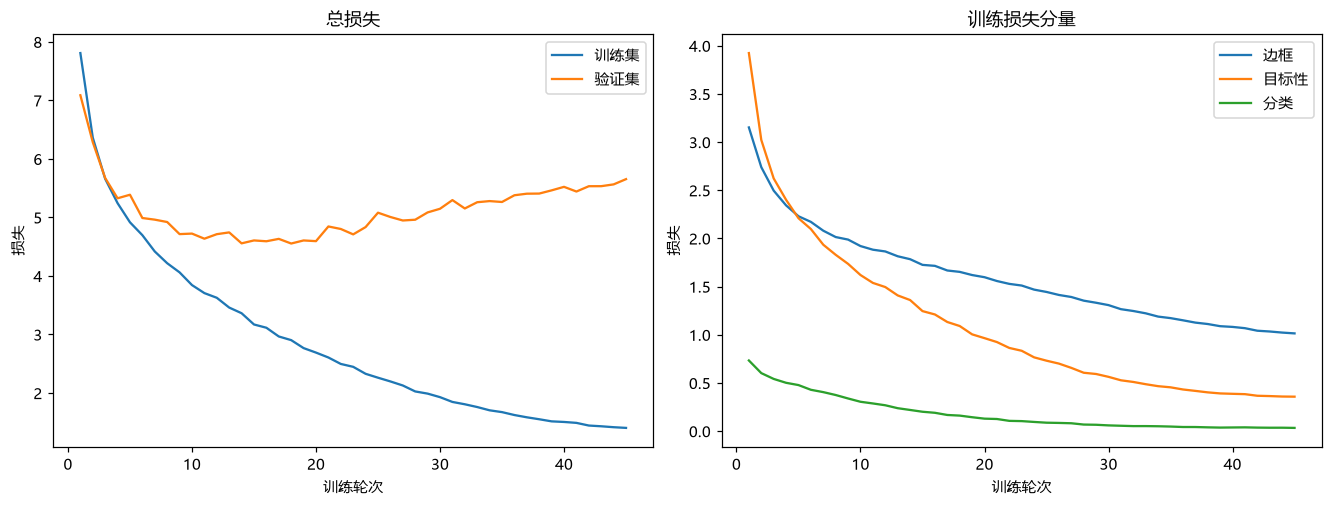

最优验证轮次 18 总训练秒数 321.4


In [5]:
EPOCHS=45
optimizer=torch.optim.AdamW(model.parameters(),lr=0.002,weight_decay=5e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=1e-4)
def epoch_detection(loader,training=False):
    model.train(training);total=np.zeros(4);seen=0;collisions=0
    with torch.set_grad_enabled(training):
        for x,targets in loader:
            outputs=model(x.to(device));loss,parts,dropped=detection_loss(outputs,targets)
            if training:
                optimizer.zero_grad();loss.backward();nn.utils.clip_grad_norm_(model.parameters(),10);optimizer.step()
            total+=np.array([loss.item(),*parts.cpu().tolist()])*len(x);seen+=len(x);collisions+=dropped
    return total/seen,collisions

history=[];best=float("inf");state=None;best_epoch=0;start=time.perf_counter()
for epoch in range(1,EPOCHS+1):
    train,dropped=epoch_detection(loaders["train"],True);val,_=epoch_detection(loaders["val"])
    history.append(dict(epoch=epoch,train_loss=train[0],val_loss=val[0],train_box=train[1],train_obj=train[2],train_cls=train[3],val_box=val[1],val_obj=val[2],val_cls=val[3],collisions=dropped,lr=optimizer.param_groups[0]["lr"],seconds=time.perf_counter()-start))
    if val[0]<best:best,state,best_epoch=val[0],copy.deepcopy(model.state_dict()),epoch
    scheduler.step()
    print("epoch",epoch,"train",round(train[0],3),"val",round(val[0],3),"seconds",round(time.perf_counter()-start),flush=True)
history_df=pd.DataFrame(history);history_df.to_csv(RESULT/"training_history.csv",index=False)
model.load_state_dict(state);torch.save({"model":state,"anchors":anchors.cpu(),"names":names,"size":SIZE,"best_epoch":best_epoch},CACHE/"tiny_yolo_best.pth")
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
axes[0].plot(history_df.epoch,history_df.train_loss,label="训练集");axes[0].plot(history_df.epoch,history_df.val_loss,label="验证集")
axes[0].set(title="总损失",xlabel="训练轮次",ylabel="损失")
for column,label in [("train_box","边框"),("train_obj","目标性"),("train_cls","分类")]:axes[1].plot(history_df.epoch,history_df[column],label=label)
axes[1].set(title="训练损失分量",xlabel="训练轮次",ylabel="损失")
for ax in axes:ax.legend()
fig.savefig(RESULT/"training_curves.png",dpi=180);plt.show()
print("最优验证轮次",best_epoch,"总训练秒数",round(time.perf_counter()-start,1))

## 5 解码 NMS 与独立测试指标

置信度为 sigmoid(objectness)×softmax(class)，每个 anchor 取最高分类。评估收集置信度≥0.001 的框，裁剪至图像范围，逐类 NMS IoU 阈值 0.5，每图最多保留 300 框。AP@0.5 为按置信度排序、同图同类一对一匹配后的全点插值 PR 面积；mAP 为三个类别 AP 的平均。

Precision/Recall 的置信阈值只根据验证集选择：在 0.05～0.70 的网格中取微平均 F1 最大者，再固定用于测试。AP 仍使用完整低阈值排序，不使用该操作阈值截断。未标注的真实目标可能被视为误检，这是该数据集的限制。

,class_name,support,Precision,Recall,F1,AP50,confidence
0,helmet,900,0.4727,0.4611,0.4668,0.4042,0.7
1,head,303,0.5374,0.2607,0.3511,0.2500,0.7
2,person,116,0.0000,0.0000,0.0000,0.0084,0.7


,Precision_micro,Recall_micro,mAP50,confidence,test_images,test_objects,best_epoch
0,0.4796,0.3745,0.2208,0.7,241,1319,18


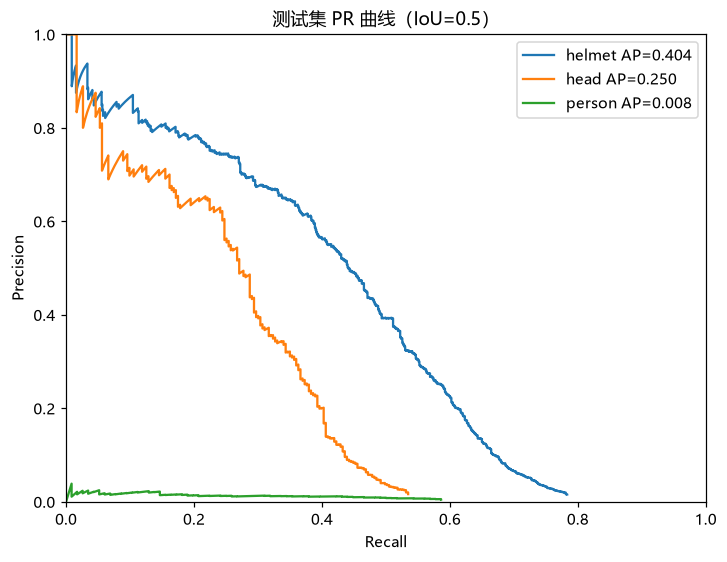

In [6]:
@torch.no_grad()
def predict_batch(x,conf=0.001):
    model.eval();outputs=model(x.to(device));boxes=[];scores=[];labels=[]
    for scale,p in enumerate(outputs):
        boxes.append(decode_scale(p,anchors[scale]).flatten(1,3))
        prob,cls=p[...,5:].softmax(-1).max(-1)
        scores.append((p[...,4].sigmoid()*prob).flatten(1));labels.append(cls.flatten(1))
    boxes=torch.cat(boxes,1).clamp(0,1);scores=torch.cat(scores,1);labels=torch.cat(labels,1)
    predictions=[]
    for b,s,c in zip(boxes,scores,labels):
        keep=(s>=conf)&((b[:,2:]-b[:,:2]).min(1).values>0)
        b,s,c=b[keep],s[keep],c[keep]
        ids=batched_nms(b,s,c,0.5)[:300]
        predictions.append({"boxes":b[ids].cpu(),"scores":s[ids].cpu(),"labels":c[ids].cpu()})
    return predictions

def collect(loader):
    pred=[];truth=[]
    for x,t in loader:pred.extend(predict_batch(x));truth.extend(t)
    return pred,truth

def match_predictions(predictions,truths,threshold=0.001):
    per_class=[]
    for c in range(3):
        n_gt=sum(int((t["labels"]==c).sum()) for t in truths)
        entries=[];matched={i:set() for i in range(len(truths))}
        for i,p in enumerate(predictions):
            for k in torch.where((p["labels"]==c)&(p["scores"]>=threshold))[0].tolist():
                entries.append((float(p["scores"][k]),i,k))
        entries.sort(reverse=True)
        tp=[];fp=[];scores=[]
        for score,i,k in entries:
            candidates=torch.where(truths[i]["labels"]==c)[0]
            candidates=[int(j) for j in candidates if int(j) not in matched[i]]
            ok=False
            if candidates:
                ious=box_iou(predictions[i]["boxes"][k:k+1],truths[i]["boxes"][candidates])[0]
                j=int(ious.argmax())
                if ious[j]>=0.5:matched[i].add(candidates[j]);ok=True
            tp.append(int(ok));fp.append(int(not ok));scores.append(score)
        tp_c=np.cumsum(tp);fp_c=np.cumsum(fp)
        recall=tp_c/max(n_gt,1);precision=tp_c/np.maximum(tp_c+fp_c,1)
        mrec=np.r_[0,recall,1];mpre=np.r_[0,precision,0]
        mpre=np.maximum.accumulate(mpre[::-1])[::-1]
        ap=np.sum(np.diff(mrec)*mpre[1:]) if n_gt else float("nan")
        per_class.append(dict(class_name=names[c],n_gt=n_gt,AP50=ap,tp=sum(tp),fp=sum(fp),precision=precision,recall=recall,scores=scores))
    return per_class

val_predictions,val_truth=collect(loaders["val"])
threshold_rows=[]
for threshold in np.arange(0.05,0.71,0.05):
    matches=match_predictions(val_predictions,val_truth,threshold)
    tp=sum(r["tp"] for r in matches);fp=sum(r["fp"] for r in matches);n=sum(r["n_gt"] for r in matches)
    p=tp/max(tp+fp,1);r=tp/max(n,1);f=2*p*r/max(p+r,1e-9)
    threshold_rows.append(dict(confidence=threshold,Precision=p,Recall=r,F1=f))
threshold_df=pd.DataFrame(threshold_rows)
confidence=float(threshold_df.loc[threshold_df.F1.idxmax(),"confidence"])
threshold_df.to_csv(RESULT/"validation_thresholds.csv",index=False)

test_predictions,test_truth=collect(loaders["test"])
matches=match_predictions(test_predictions,test_truth)
operating=match_predictions(test_predictions,test_truth,confidence)
metric_rows=[]
for ap,op in zip(matches,operating):
    p=op["tp"]/max(op["tp"]+op["fp"],1);r=op["tp"]/max(op["n_gt"],1)
    metric_rows.append(dict(class_name=op["class_name"],support=op["n_gt"],Precision=p,Recall=r,F1=2*p*r/max(p+r,1e-9),AP50=ap["AP50"],confidence=confidence))
metric_df=pd.DataFrame(metric_rows);metric_df.to_csv(RESULT/"class_metrics.csv",index=False)
tp=sum(r["tp"] for r in operating);fp=sum(r["fp"] for r in operating);n=sum(r["n_gt"] for r in operating)
summary={"Precision_micro":tp/max(tp+fp,1),"Recall_micro":tp/max(n,1),"mAP50":float(metric_df.AP50.mean()),"confidence":confidence,"test_images":len(test_truth),"test_objects":n,"best_epoch":best_epoch}
pd.DataFrame([summary]).to_csv(RESULT/"metrics.csv",index=False)
serial=[]
for p,t in zip(test_predictions,test_truth):
    serial.append(dict(filename=records[t["id"]]["filename"],**{k:v.tolist() for k,v in p.items()}))
(RESULT/"test_predictions.json").write_text(json.dumps(serial),encoding="utf-8")
display(metric_df.round(4));display(pd.DataFrame([summary]).round(4))
fig,ax=plt.subplots(figsize=(6.5,5),constrained_layout=True)
for r in matches:ax.plot(r["recall"],r["precision"],label=f'{r["class_name"]} AP={r["AP50"]:.3f}')
ax.set(xlabel="Recall",ylabel="Precision",title="测试集 PR 曲线（IoU=0.5）",xlim=(0,1),ylim=(0,1));ax.legend()
fig.savefig(RESULT/"precision_recall.png",dpi=180);plt.show()

## 6 尺度 遮挡扰动与检测可视化

尺度按 letterbox 后的真实框面积划分，小目标<32²，中目标32²～96²，大目标≥96²。固定操作阈值，统计正确分类且 IoU≥0.5 的召回率；预测按置信度排序，一对一匹配，统计所有目标的实际支持数。没有目标的组记为 NaN。

原 occluded 属性先统计；如果缺少可靠遮挡标签，就不声称测得了真实遮挡子集性能。另做可控测试扰动：在每个真实目标框中心用灰块覆盖框宽高的 40%（面积约 16%，重叠时可能更多），保持原真值与阈值，单独报告其召回变化。这是利用真值构造的合成压力测试，不等于自然遮挡评估，也不用于训练和选模。

,size,support,matched,Recall
0,小(<32px),1156,448,0.387543
1,中(32~96px),159,46,0.289308
2,大(≥96px),4,0,0.000000


,condition,Recall
0,原图,0.374526
1,目标中心灰块扰动,0.137983


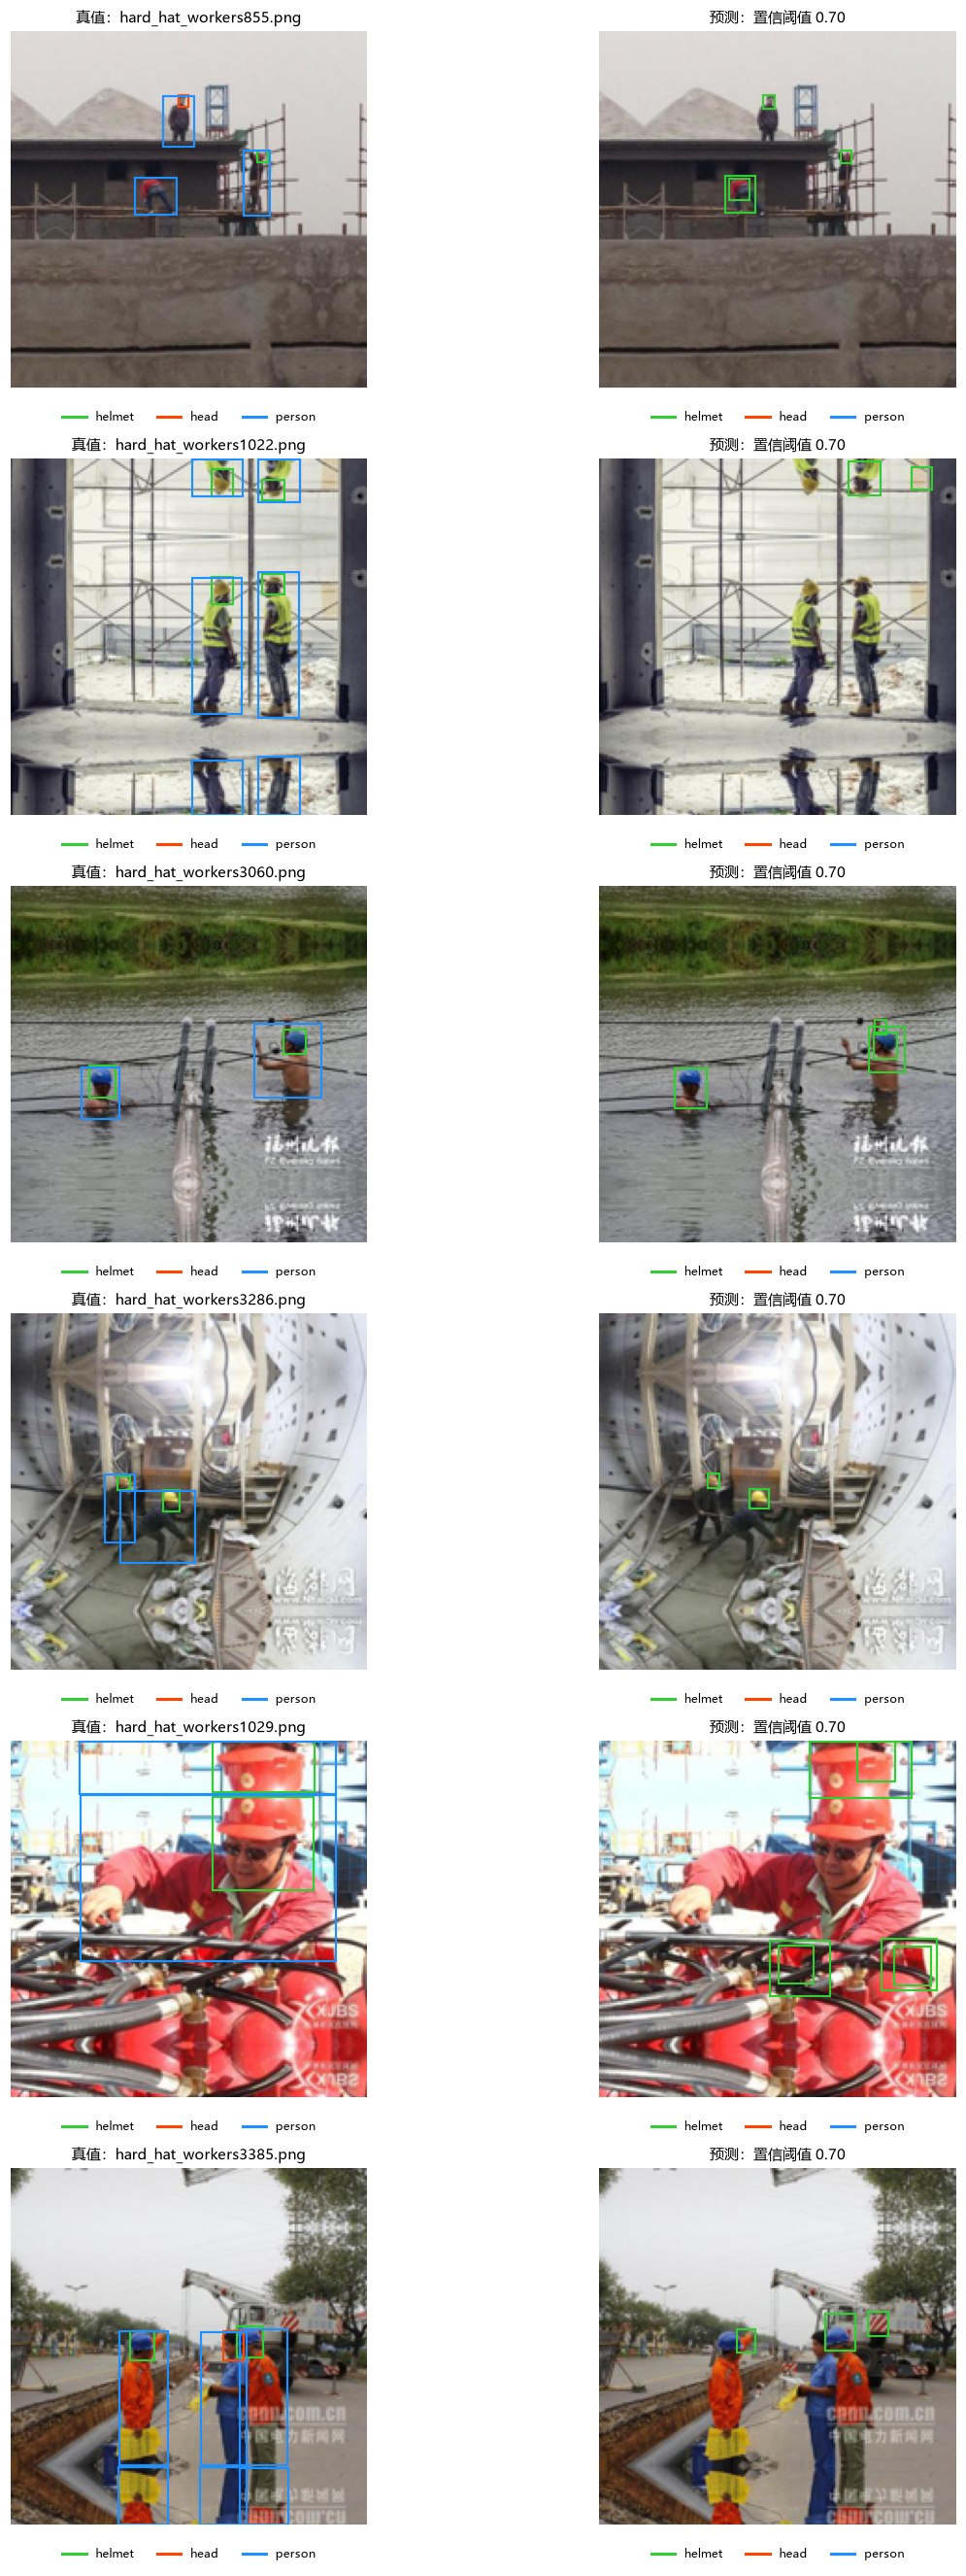

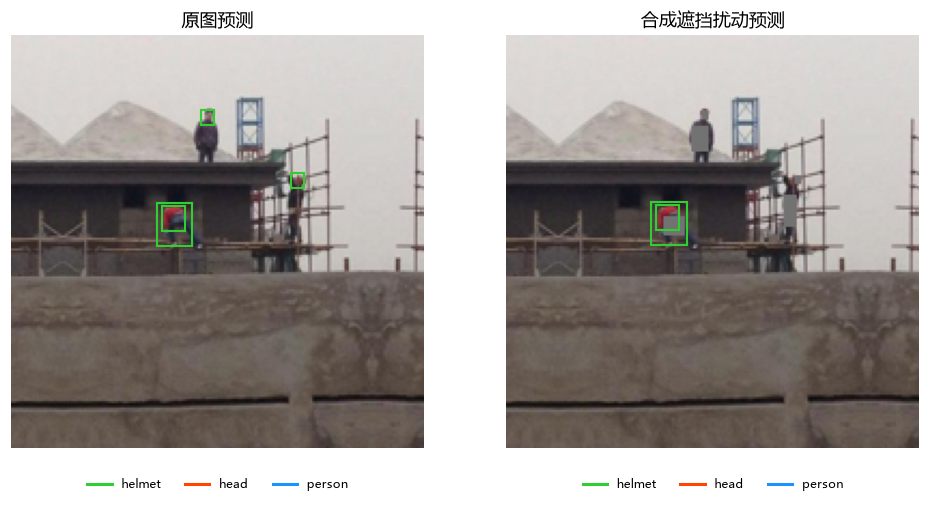

实测单张推理毫秒 3.01


In [7]:
def size_recall(predictions,truths):
    totals=np.zeros(3,dtype=int);correct=np.zeros(3,dtype=int)
    for p,t in zip(predictions,truths):
        b=t["boxes"];area=(b[:,2:]-b[:,:2]).prod(1)*SIZE**2
        size=torch.where(area<32**2,0,torch.where(area<96**2,1,2))
        for s in size.tolist():totals[s]+=1
        used=set()
        for k in p["scores"].argsort(descending=True).tolist():
            if p["scores"][k]<confidence:continue
            ids=[j for j in range(len(b)) if j not in used and t["labels"][j]==p["labels"][k]]
            if not ids:continue
            iou=box_iou(p["boxes"][k:k+1],b[ids])[0];best=int(iou.argmax())
            if iou[best]>=0.5:
                j=ids[best];used.add(j);correct[int(size[j])]+=1
    return pd.DataFrame({"size":["小(<32px)","中(32~96px)","大(≥96px)"],"support":totals,"matched":correct,"Recall":np.divide(correct,totals,out=np.full(3,np.nan),where=totals>0)})

scale_df=size_recall(test_predictions,test_truth)
scale_df.to_csv(RESULT/"scale_recall.csv",index=False,encoding="utf-8-sig");display(scale_df)
occluded_predictions=[];occluded_images=[]
for x,targets in loaders["test"]:
    perturbed=x.clone()
    for i,t in enumerate(targets):
        for b in t["boxes"]:
            center=(b[:2]+b[2:])/2*SIZE;half=(b[2:]-b[:2])*SIZE*0.2
            x1,y1=(center-half).floor().int().clamp(0,SIZE).tolist();x2,y2=(center+half).ceil().int().clamp(0,SIZE).tolist()
            perturbed[i,:,y1:y2,x1:x2]=114/255
    occluded_predictions.extend(predict_batch(perturbed));occluded_images.extend(perturbed)
occ_matches=match_predictions(occluded_predictions,test_truth,confidence)
occ_summary=pd.DataFrame([{"condition":"原图","Recall":summary["Recall_micro"]},
    {"condition":"目标中心灰块扰动","Recall":sum(r["tp"] for r in occ_matches)/n}])
occ_summary.to_csv(RESULT/"occlusion_stress.csv",index=False,encoding="utf-8-sig");display(occ_summary)

colors=["limegreen","orangered","dodgerblue"]
def draw_boxes(ax,image,boxes,labels,scores=None):
    ax.imshow(image);ax.axis("off")
    for k,(b,c) in enumerate(zip(boxes,labels)):
        if scores is not None and scores[k]<confidence:continue
        x1,y1,x2,y2=b.tolist();c=int(c)
        ax.add_patch(Rectangle((x1*SIZE,y1*SIZE),(x2-x1)*SIZE,(y2-y1)*SIZE,fill=False,edgecolor=colors[c],linewidth=1.4))
    from matplotlib.lines import Line2D
    handles=[Line2D([0],[0],color=color,lw=2,label=name) for color,name in zip(colors,names)]
    ax.legend(handles=handles,loc="lower center",bbox_to_anchor=(0.5,-0.13),ncol=3,fontsize=8,frameon=False)

# 固定展示测试清单前六张，左为真值、右为预测，使用相同缩放坐标。
fig,axes=plt.subplots(6,2,figsize=(11,24),constrained_layout=True)
for j in range(6):
    t=test_truth[j];p=test_predictions[j];im=images[t["id"]]
    draw_boxes(axes[j,0],im,t["boxes"],t["labels"])
    draw_boxes(axes[j,1],im,p["boxes"],p["labels"],p["scores"])
    axes[j,0].set_title("真值："+records[t["id"]]["filename"],fontsize=10)
    axes[j,1].set_title(f"预测：置信阈值 {confidence:.2f}",fontsize=10)
fig.savefig(RESULT/"detection_examples.png",dpi=160);plt.show()
for j in range(6):
    t=test_truth[j];p=test_predictions[j]
    fig,axes=plt.subplots(1,2,figsize=(9,4.5),constrained_layout=True)
    draw_boxes(axes[0],images[t["id"]],t["boxes"],t["labels"])
    draw_boxes(axes[1],images[t["id"]],p["boxes"],p["labels"],p["scores"])
    axes[0].set_title("真实标注");axes[1].set_title("模型预测")
    fig.savefig(RESULT/f"example_{j+1}.png",dpi=180);plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(9,4.5),constrained_layout=True)
j=0;t=test_truth[j]
draw_boxes(axes[0],images[t["id"]],test_predictions[j]["boxes"],test_predictions[j]["labels"],test_predictions[j]["scores"])
draw_boxes(axes[1],occluded_images[j].permute(1,2,0),occluded_predictions[j]["boxes"],occluded_predictions[j]["labels"],occluded_predictions[j]["scores"])
axes[0].set_title("原图预测");axes[1].set_title("合成遮挡扰动预测")
fig.savefig(RESULT/"occlusion_example.png",dpi=180);plt.show()

# 只计模型前向+解码+NMS，不包括文件读取；CPU实测，不能外推其他设备。
sample=next(iter(loaders["test"]))[0][:1]
for _ in range(3):predict_batch(sample)
if device.type=="cuda":torch.cuda.synchronize()
tic=time.perf_counter()
for _ in range(20):predict_batch(sample)
if device.type=="cuda":torch.cuda.synchronize()
latency=(time.perf_counter()-tic)/20
pd.DataFrame([dict(device=str(device),input_size=SIZE,batch_size=1,latency_ms=latency*1000,FPS=1/latency)]).to_csv(RESULT/"inference_speed.csv",index=False)
print("实测单张推理毫秒",round(latency*1000,2))

## 分析依据与限制

按实际 class_metrics.csv、scale_recall.csv 和可视化分析漏检、误检与类别混淆，特别注意 person 类稀少、小目标在 192 输入下像素不足以及密集目标的 anchor 冲突。训练损失下降不代表检测达到可部署水平。宏平均 mAP 会保留稀少 person 类的低 AP，不隐藏不理想结果。

数据规模为本机 CPU 子集，加入 person 图片提高覆盖后，类别分布与原始全量数据不同；感知哈希只降低近重复泄漏风险，不能保证所有相似场景都被识别。原数据可能存在漏标，若没有自然遮挡标注，则合成灰块只能用于压力测试。模型输入、层数与训练预算均小于标准 YOLO 系列，不能直接与官方模型的 mAP 或实时速度比较。

实际训练中最低验证损失在第 18 轮，后续训练损失继续下降而验证损失升高，存在过拟合。241 张独立测试图含 1319 个目标，mAP@0.5 为 0.2208，固定验证阈值 0.70 后的微平均 Precision 为 0.4796、Recall 为 0.3745。helmet、head、person 的 AP50 分别为 0.4042、0.2500、0.0084；person 的操作阈值召回为零，不能认为本模型已可靠实现人员检测。

小、中、大目标召回分别为 0.3875、0.2893、0，支持数为 1156、159、4；类别与尺度分布混杂，尤其大目标只有 4 个，不能归纳为大目标普遍更难。原始 occluded 属性的 8698 个值全部为零；合成遮挡后召回降至 0.1380，只能说明该扰动下的敏感性。六张可视化用统一颜色图例区分类别，框置信度保存在 JSON 中，避免密集文字覆盖图像。